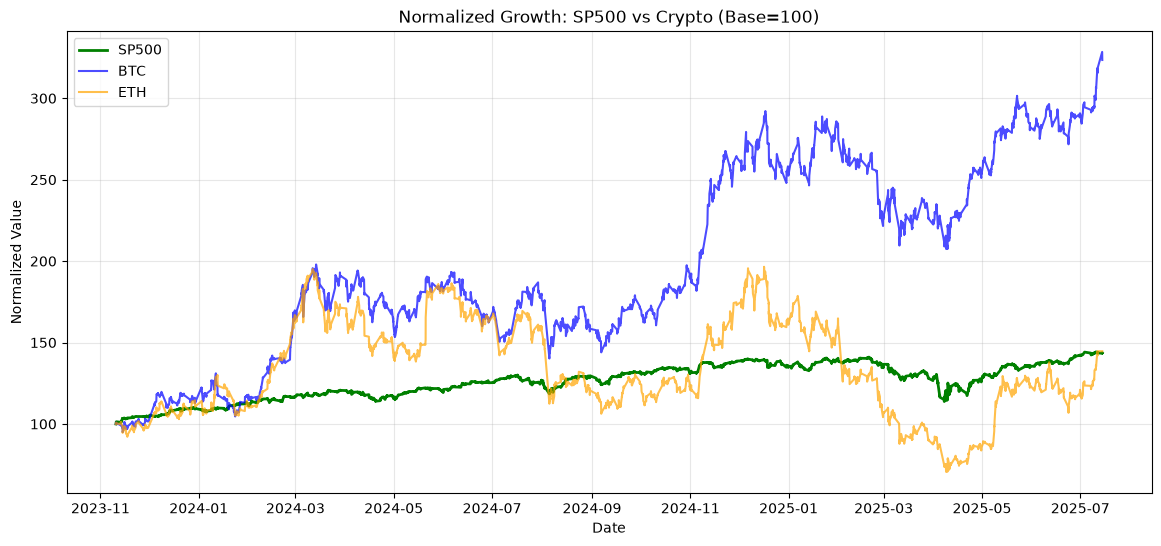

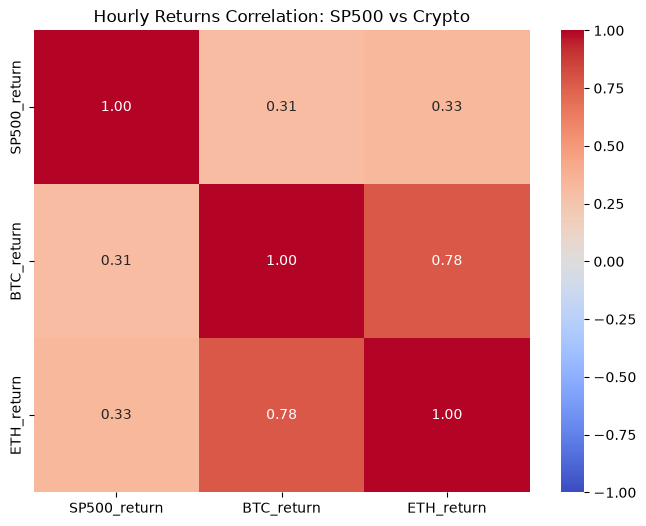

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Clean කරපු SP500 data එක Load කිරීම
processed_path = r"E:\Innovus\Documents\Agentic-AI-Based-Market-Intelligence-Framework-For-Bitcoin-and-Ethereum-Trading\Vibhu Kalpitha\data\02_processed\sp500_cleaned_1h.csv"
df = pd.read_csv(processed_path)
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# 2. Normalize Prices to compare SP500 with Crypto
# ඔක්කොම එකම base එකකට (Base 100) ගෙනල්ලා trend එක බලමු
df_norm = (df[['SP500_Close', 'BTC_close', 'ETH_close']] / df[['SP500_Close', 'BTC_close', 'ETH_close']].iloc[0]) * 100

plt.figure(figsize=(14, 6))
plt.plot(df_norm.index, df_norm['SP500_Close'], label='SP500', color='green', linewidth=2)
plt.plot(df_norm.index, df_norm['BTC_close'], label='BTC', color='blue', alpha=0.7)
plt.plot(df_norm.index, df_norm['ETH_close'], label='ETH', color='orange', alpha=0.7)

plt.title("Normalized Growth: SP500 vs Crypto (Base=100)")
plt.ylabel("Normalized Value")
plt.xlabel("Date")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Correlation between SP500 Returns and Crypto Returns
# SP500 උඩට යද්දී BTC වලට මොකද වෙන්නේ කියලා බලමු
df['SP500_return'] = df['SP500_Close'].pct_change()
df['BTC_return'] = df['BTC_close'].pct_change()
df['ETH_return'] = df['ETH_close'].pct_change()

corr = df[['SP500_return', 'BTC_return', 'ETH_return']].dropna().corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Hourly Returns Correlation: SP500 vs Crypto")
plt.show()